In [293]:
# read data
from xror import XROR

from xgboost import XGBClassifier
# from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support

import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R

import matplotlib.pyplot as plt
import seaborn as sns

from os import listdir
from os.path import isfile, join

In [294]:
PAST_TIME = 0.2
FUTURE_TIME = 0.1

In [295]:
# TODO: Replace *h_movement with movement extent across x, y, z axes
# TODO: Replace rotation with rotation speed

def parse_events(frames, events):
    cut_time = [x[0] for x in events[0]['floatData']]
    hand_used = [x[3] for x in events[0]['otherData']]
    frame_time = np.array([x[0] for x in frames])

    # cut_frame_id = [np.argmin(np.abs(ct - frame_time)) for ct in cut_time]

    cut_window_start_frame_id = [np.argmin(np.abs(ct - PAST_TIME - frame_time)) for ct in cut_time]
    cut_window_end_frame_id = [np.argmin(np.abs(ct + FUTURE_TIME - frame_time)) for ct in cut_time]

    df = []
    for i in range(len(cut_time)):
        start = cut_window_start_frame_id[i]
        end = cut_window_end_frame_id[i]
        
        lh_trail = frames[start:end, 8:11]
        lh_mean_pos = np.mean(lh_trail, axis=0)
        lh_deltas = np.diff(lh_trail, axis=0)
        lh_movement = np.sqrt(np.sum(lh_deltas*lh_deltas))
        lh_speed = np.mean(np.sqrt(np.sum(lh_deltas*lh_deltas, axis=1)))

        rh_trail = frames[start:end, 15:18]
        rh_mean_pos = np.mean(rh_trail, axis=0)
        rh_deltas = np.diff(rh_trail, axis=0)
        rh_movement = np.sqrt(np.sum(rh_deltas*rh_deltas))
        rh_speed = np.mean(np.sqrt(np.sum(rh_deltas*rh_deltas, axis=1)))

        lh_quats = frames[start:end, 11:15]
        lh_rots = R.from_quat(lh_quats)
        lh_mean_ori = R.mean(lh_rots).as_quat(canonical=True)
        lh_delta_rots = [lh_rots[i].inv() * lh_rots[i+1] for i in range(lh_quats.shape[0]-1)]
        lh_rotation = sum([rot.magnitude() for rot in lh_delta_rots])
        
        rh_quats = frames[start:end, 18:22]
        rh_rots = R.from_quat(rh_quats)
        rh_mean_ori = R.mean(rh_rots).as_quat(canonical=True)
        rh_delta_rots = [rh_rots[i].inv() * rh_rots[i+1] for i in range(rh_quats.shape[0]-1)]
        rh_rotation = sum([rot.magnitude() for rot in rh_delta_rots])

        df.append(dict(
            lh_movement=lh_movement,
            rh_movement=rh_movement,
            lh_speed=lh_speed,
            rh_speed=rh_speed,
            lh_mean_x=lh_mean_pos[0],
            lh_mean_y=lh_mean_pos[1],
            lh_mean_z=lh_mean_pos[2],
            rh_mean_x=rh_mean_pos[0],
            rh_mean_y=rh_mean_pos[1],
            rh_mean_z=rh_mean_pos[2],
            lh_mean_ori_x=lh_mean_ori[0],
            lh_mean_ori_y=lh_mean_ori[1],
            lh_mean_ori_z=lh_mean_ori[2],
            lh_mean_ori_w=lh_mean_ori[3],
            rh_mean_ori_x=rh_mean_ori[0],
            rh_mean_ori_y=rh_mean_ori[1],
            rh_mean_ori_z=rh_mean_ori[2],
            rh_mean_ori_w=rh_mean_ori[3],
            lh_rotation=lh_rotation,
            rh_rotation=rh_rotation,
            hand_used=hand_used[i]
        ))
        # print(f'{lh_movement} {rh_movement} {lh_speed} {rh_speed} {hand_used[i]}')

    return df

In [296]:
folder = 'boxrr-23/00009567-9cfd-4310-a43f-ecf0944f6bbd'
files = [f for f in listdir(folder) if isfile(join(folder, f))]

events = []
frames = []

df = []

for filename in files[:20]:
    if '.xror' not in filename:
        continue
    with open(join(folder, filename), 'rb') as f:
        file = f.read()
    xror = XROR.unpack(file)
    events = xror.data['events']
    frames = np.array(xror.data['frames'])
    df += parse_events(frames, events)

df = pd.DataFrame.from_records(df)

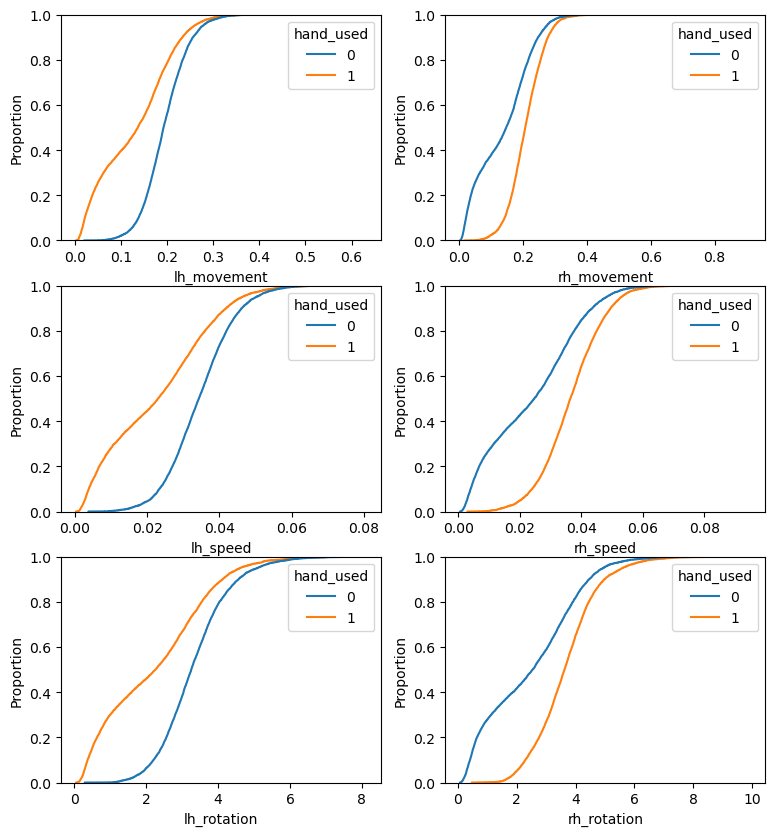

In [297]:
fig, axes = plt.subplots(3, 2)
sns.ecdfplot(df, x='lh_movement', hue='hand_used', ax=axes[0, 0])
sns.ecdfplot(df, x='rh_movement', hue='hand_used', ax=axes[0, 1])
sns.ecdfplot(df, x='lh_speed', hue='hand_used', ax=axes[1, 0])
sns.ecdfplot(df, x='rh_speed', hue='hand_used', ax=axes[1, 1])
sns.ecdfplot(df, x='lh_rotation', hue='hand_used', ax=axes[2, 0])
sns.ecdfplot(df, x='rh_rotation', hue='hand_used', ax=axes[2, 1])
plt.subplots_adjust(top=1.7, bottom=0.1, right=1.2, left=0.1)

In [301]:
train, test = train_test_split(df, test_size=.2, random_state=777)

pos_change_vars = ['lh_speed', 'rh_speed']
pos_vars = ['lh_mean_x', 'lh_mean_y', 'lh_mean_z', 'rh_mean_x', 'rh_mean_y', 'rh_mean_z']
rot_change_vars = ['lh_rotation', 'rh_rotation']
rot_vars = ['lh_mean_ori_x', 'lh_mean_ori_y', 'lh_mean_ori_z', 'lh_mean_ori_w', 'rh_mean_ori_x', 'rh_mean_ori_y', 'rh_mean_ori_z', 'rh_mean_ori_w']

ind_vars = pos_change_vars + rot_change_vars + pos_vars + rot_vars

dep_var = 'hand_used'
X_train = train[ind_vars]
y_train = train[dep_var]
X_test = test[ind_vars]
y_test = test[dep_var]

# create model instance
bst = XGBClassifier(n_estimators=40, max_depth=5, learning_rate=0.3, objective='binary:logistic')
# fit model
bst.fit(X_train, y_train)
# make predictions
preds_train = bst.predict(X_train)
preds = bst.predict(X_test)

# plt.scatter(range(y_test.shape[0]), y_test, label="Ground truth")
# plt.scatter(range(y_test.shape[0]), preds+0.01, label="Prediction")
# plt.legend(bbox_to_anchor=(1.35, 0.5));

print(f"Train precision, recall, F-score: {precision_recall_fscore_support(y_train, preds_train, average='micro')[:-1]}")
print(f"Test precision, recall, F-score:  {precision_recall_fscore_support(y_test, preds, average='micro')[:-1]}")

bst.get_booster().get_score(importance_type='gain')

Train precision, recall, F-score: (0.8788829005389515, 0.8788829005389515, 0.8788829005389515)
Test precision, recall, F-score:  (0.7637147335423198, 0.7637147335423198, 0.7637147335423198)


{'lh_speed': 76.04449462890625,
 'rh_speed': 61.39568328857422,
 'lh_rotation': 38.403831481933594,
 'rh_rotation': 20.36783790588379,
 'lh_mean_x': 3.224015474319458,
 'lh_mean_y': 5.9753923416137695,
 'lh_mean_z': 2.824753999710083,
 'rh_mean_x': 3.2003047466278076,
 'rh_mean_y': 7.310579776763916,
 'rh_mean_z': 3.5469484329223633,
 'lh_mean_ori_x': 9.195323944091797,
 'lh_mean_ori_y': 10.73208999633789,
 'lh_mean_ori_z': 4.067069053649902,
 'lh_mean_ori_w': 4.964782238006592,
 'rh_mean_ori_x': 7.3491363525390625,
 'rh_mean_ori_y': 6.550937652587891,
 'rh_mean_ori_z': 3.734144687652588,
 'rh_mean_ori_w': 6.533054828643799}